Week 6 - Feature Engineering

*   Engineer new features
*   Add a school district feature by spatially joining each property's coordinates to the CA School District Areas 2024-2025 boundaries.
*   Re-train the models with the updated feature set.
*   **Deliverable**: this notebook + a table comparing old vs. new feature sets



In [1]:
import os
import glob
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import KFold
from sklearn.neighbors import BallTree
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

try:
    import geopandas as gpd
except ImportError:
    import subprocess, sys
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "geopandas"])
    import geopandas as gpd

warnings.filterwarnings("ignore")

from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [2]:
CSV_DIR = "/content/drive/MyDrive/csv"
DATA_DIR = "/content/drive/MyDrive/output"
DISTRICT_FILE = "/content/drive/MyDrive/school_districts/california_school_district_areas_2024-25.geojson"

X_MONTHS = 24
DT_DEPTH = 20
RF_TREES = 100

In [3]:
def build_unscaled_file(out_path):
    needed = ["ClosePrice", "CloseDate", "PropertyType", "PropertySubType", "LivingArea", "BedroomsTotal",
              "BathroomsTotalInteger", "LotSizeSquareFeet", "YearBuilt", "City", "PostalCode",
              "Latitude", "Longitude", "latfilled", "lonfilled"]

    files = glob.glob(os.path.join(CSV_DIR, "CRMLSSold*.csv"))
    print(f"Found {len(files)} files")
    raw = pd.concat([pd.read_csv(f, usecols=lambda c: c in needed, low_memory=False) for f in files],
                    ignore_index=True)
    print(f"Loaded {len(raw):,} rows")

    raw = raw[(raw["PropertyType"] == "Residential") & (raw["PropertySubType"] == "SingleFamilyResidence")].copy()
    raw["CloseDate"] = pd.to_datetime(raw["CloseDate"], errors="coerce")
    print(f"Rows after filtering to Residential / SingleFamilyResidence: {len(raw):,}")

    bad_rows = {
        "ClosePrice":            (raw["ClosePrice"] <= 10_000) | (raw["ClosePrice"] > 20_000_000),
        "LivingArea":            (raw["LivingArea"] <= 100) | (raw["LivingArea"] > 15_000),
        "BedroomsTotal":         (raw["BedroomsTotal"] <= 0) | (raw["BedroomsTotal"] > 12),
        "BathroomsTotalInteger": (raw["BathroomsTotalInteger"] <= 0) | (raw["BathroomsTotalInteger"] > 12),
        "LotSizeSquareFeet":     (raw["LotSizeSquareFeet"] <= 100) | (raw["LotSizeSquareFeet"] > 1_000_000),
        "YearBuilt":             (raw["YearBuilt"] < 1800) | (raw["YearBuilt"] > 2026),
    }
    for col, mask in bad_rows.items():
        print(f"{col}: {mask.sum():,} impossible values set to missing")
        raw.loc[mask, col] = np.nan

    raw = raw[raw["ClosePrice"].notna()].copy()
    for col in ["LivingArea", "BedroomsTotal", "BathroomsTotalInteger", "LotSizeSquareFeet", "YearBuilt"]:
        raw[col] = raw[col].fillna(raw[col].median())
    raw["City"] = raw["City"].fillna("Unknown")
    raw["PostalCode"] = raw["PostalCode"].fillna("Unknown")

    month = raw["CloseDate"].dt.to_period("M")
    test_month = month.max()
    window_start = (test_month - X_MONTHS).to_timestamp()
    window_end = test_month.to_timestamp()
    test_part = raw[month == test_month]
    train_part = raw[(raw["CloseDate"] >= window_start) & (raw["CloseDate"] < window_end)]

    keep = [c for c in ["ClosePrice", "CloseDate", "LivingArea", "BedroomsTotal", "BathroomsTotalInteger",
                        "LotSizeSquareFeet", "YearBuilt", "City", "PostalCode",
                        "Latitude", "Longitude", "latfilled", "lonfilled"] if c in raw.columns]
    out = pd.concat([train_part[keep].assign(split="train"), test_part[keep].assign(split="test")],
                    ignore_index=True)

    os.makedirs(os.path.dirname(out_path), exist_ok=True)
    out.to_csv(out_path, index=False)
    print(f"Saved {out_path} ({len(out):,} rows). Test month: {test_month}")


In [4]:
unscaled_path = os.path.join(DATA_DIR, "cleaned_data_unscaled.csv")

if os.path.exists(unscaled_path):
    print("Found cleaned_data_unscaled.csv")
else:
    print("cleaned_data_unscaled.csv not found, so I'm building it from the raw files...")
    build_unscaled_file(unscaled_path)

data = pd.read_csv(unscaled_path)
data["CloseDate"] = pd.to_datetime(data["CloseDate"])

print("\nRows:", len(data))
print(data["split"].value_counts())
data.head()


Found cleaned_data_unscaled.csv

Rows: 276550
split
train    265372
test      11178
Name: count, dtype: int64


,ClosePrice,CloseDate,LivingArea,BedroomsTotal,BathroomsTotalInteger,LotSizeSquareFeet,YearBuilt,City,PostalCode,Latitude,Longitude,latfilled,lonfilled,split
0,1370000.0,2026-03-23,1860.0,4.0,3.0,6390.0,1976.0,San Jose,95136,37.272409,-121.876701,NaN,NaN,train
1,7200000.0,2026-03-27,2972.0,4.0,5.0,5625.0,1902.0,Palo Alto,94301,37.440060,-122.154345,NaN,NaN,train
2,1240000.0,2026-03-31,1980.0,3.0,2.0,5000.0,1973.0,La Palma,90623,33.852090,-118.045009,NaN,NaN,train
3,2650000.0,2026-03-30,2973.0,4.0,4.0,10454.0,2006.0,Scotts Valley,95066,37.072914,-122.003413,NaN,NaN,train
4,830000.0,2026-03-31,1116.0,3.0,2.0,6285.0,1944.0,Lakewood,90712,33.862645,-118.140949,NaN,NaN,train


In [5]:
numeric_base = ["LivingArea", "BedroomsTotal", "BathroomsTotalInteger", "LotSizeSquareFeet", "YearBuilt"]

print("Missing values in the numeric columns:")
print(data[numeric_base + ["ClosePrice"]].isna().sum())
print("\nMissing City / PostalCode:", data["City"].isna().sum(), "/", data["PostalCode"].isna().sum())

df = data.copy()
df["City"] = df["City"].fillna("Unknown")
df["PostalCode"] = df["PostalCode"].fillna("Unknown")


Missing values in the numeric columns:
LivingArea               0
BedroomsTotal            0
BathroomsTotalInteger    0
LotSizeSquareFeet        0
YearBuilt                0
ClosePrice               0
dtype: int64

Missing City / PostalCode: 0 / 0


In [6]:
df["bed_bath_ratio"] = df["BedroomsTotal"] / df["BathroomsTotalInteger"] # bedrooms / bathrooms

df["property_age"] = df["CloseDate"].dt.year - df["YearBuilt"] # sale year - year built
print("Homes with a negative age (sold before the build year):", (df["property_age"] < 0).sum())
df["property_age"] = df["property_age"].clip(lower=0)

df["sqft_per_bedroom"] = df["LivingArea"] / df["BedroomsTotal"] # spacious vs cramped homes
df["lot_to_living"] = df["LotSizeSquareFeet"] / df["LivingArea"]  # land vs size
df["total_rooms"] = df["BedroomsTotal"] + df["BathroomsTotalInteger"] # overall home size

df[["bed_bath_ratio", "property_age", "sqft_per_bedroom", "lot_to_living", "total_rooms"]].describe().round(2)


Homes with a negative age (sold before the build year): 26


,bed_bath_ratio,property_age,sqft_per_bedroom,lot_to_living,total_rooms
count,276550.00,276550.00,276550.00,276550.00,276550.00
mean,1.46,49.41,579.11,8.81,6.11
std,0.47,27.59,195.31,33.44,1.86
min,0.25,0.00,35.00,0.04,2.00
25%,1.00,27.00,447.00,2.99,5.00
50%,1.50,49.00,540.67,4.22,6.00
75%,1.50,69.00,664.00,5.95,7.00
max,6.00,225.00,4688.00,7820.00,24.00


In [7]:
# cleaning coordinates - unusable coordinates get NaN.
def in_california(lat, lon):
    return lat.between(32.0, 42.5) & lon.between(-125.0, -114.0)

df["lat"] = df["Latitude"]
df["lon"] = df["Longitude"]
good = in_california(df["lat"], df["lon"])
print(f"Rows with usable Latitude/Longitude: {good.sum():,} of {len(df):,}")

if {"latfilled", "lonfilled"}.issubset(df.columns):
    can_fill = ~good & in_california(df["latfilled"], df["lonfilled"])
    df.loc[can_fill, "lat"] = df.loc[can_fill, "latfilled"]
    df.loc[can_fill, "lon"] = df.loc[can_fill, "lonfilled"]
    print(f"Recovered {can_fill.sum():,} rows using latfilled/lonfilled")
    good = in_california(df["lat"], df["lon"])

df.loc[~good, ["lat", "lon"]] = np.nan
print(f"Rows with no usable coordinates (will get 'Unknown' district): {(~good).sum():,} ({(~good).mean():.1%})")


Rows with usable Latitude/Longitude: 275,792 of 276,550
Recovered 0 rows using latfilled/lonfilled
Rows with no usable coordinates (will get 'Unknown' district): 758 (0.3%)


In [8]:
DISTRICT_URL = "https://gis.data.ca.gov/api/download/v1/items/b0e3b936426a47ce9d9a2e77e2bb86cc/geojson?layers=0"

if not os.path.exists(DISTRICT_FILE):
    print("District file not found at:", DISTRICT_FILE)
    print("Trying to download it...")
    try:
        import requests
        r = requests.get(DISTRICT_URL, timeout=600)
        r.raise_for_status()
        if len(r.content) < 100_000:
            raise RuntimeError("response is too small to be the boundary file: " + r.text[:200])
        os.makedirs(os.path.dirname(DISTRICT_FILE), exist_ok=True)
        with open(DISTRICT_FILE, "wb") as f:
            f.write(r.content)
        print("Downloaded.")
    except Exception as e:
        raise FileNotFoundError(
            f"Could not download the district file ({e}). Download the Shapefile or GeoJSON from the data.ca.gov "
            f"link in the task doc, upload it to Drive, and set DISTRICT_FILE to its path.")

districts = gpd.read_file(DISTRICT_FILE)
print("District polygons:", len(districts))
print("Columns:", districts.columns.tolist())
print("Coordinate system:", districts.crs)
districts.drop(columns="geometry").head()


District polygons: 937
Columns: ['OBJECTID', 'Year', 'FedID', 'CDCode', 'CDSCode', 'CountyName', 'DistrictName', 'DistrictType', 'GradeLow', 'GradeHigh', 'GradeLowCensus', 'GradeHighCensus', 'AssistStatus', 'CongressUS', 'SenateCA', 'AssemblyCA', 'UpdateNotes', 'EnrollTotal', 'EnrollCharter', 'EnrollNonCharter', 'AAcount', 'AApct', 'AIcount', 'AIpct', 'AScount', 'ASpct', 'FIcount', 'FIpct', 'HIcount', 'HIpct', 'PIcount', 'PIpct', 'WHcount', 'WHpct', 'MRcount', 'MRpct', 'NRcount', 'NRpct', 'ELcount', 'ELpct', 'FOScount', 'FOSpct', 'HOMcount', 'HOMpct', 'MIGcount', 'MIGpct', 'SWDcount', 'SWDpct', 'SEDcount', 'SEDpct', 'DistrctAreaSqMi', 'Shape__Area', 'Shape__Length', 'geometry']
Coordinate system: EPSG:4326


,OBJECTID,Year,FedID,CDCode,CDSCode,CountyName,DistrictName,DistrictType,GradeLow,GradeHigh,...,HOMpct,MIGcount,MIGpct,SWDcount,SWDpct,SEDcount,SEDpct,DistrctAreaSqMi,Shape__Area,Shape__Length
0,1,2024-25,0601770,0161119,01611190000000,Alameda,Alameda Unified,Unified,PK,12,...,0.7,0,0.0,1356,12.6,3958,36.7,11.248939,4.755489e+07,56522.982683
1,2,2024-25,0601860,0161127,01611270000000,Alameda,Albany City Unified,Unified,PK,12,...,0.6,0,0.0,357,9.7,1184,32.1,1.789984,7.096327e+06,12696.382797
2,3,2024-25,0604740,0161143,01611430000000,Alameda,Berkeley Unified,Unified,PK,12,...,2.1,0,0.0,1111,12.1,2686,29.3,10.434329,4.364648e+07,43695.341538
3,4,2024-25,0607800,0161150,01611500000000,Alameda,Castro Valley Unified,Unified,PK,12,...,1.3,0,0.0,1113,11.6,3728,39.0,66.885571,2.838285e+08,142492.767565
4,5,2024-25,0612630,0161168,01611680000000,Alameda,Emery Unified,Unified,PK,12,...,2.5,0,0.0,81,13.7,412,69.8,1.273929,5.363392e+06,13741.272894


In [9]:
def find_col(gdf, wanted):
    wanted = wanted.lower()
    for c in gdf.columns:
        c_low = c.lower()
        if c_low == wanted or (len(c_low) >= 8 and wanted.startswith(c_low)):
            return c
    return None

name_col = find_col(districts, "DistrictName")
type_col = find_col(districts, "DistrictType")
code_col = find_col(districts, "CDCode")
print("Name column:", name_col, "| Type column:", type_col, "| Code column:", code_col)
if name_col is None and code_col is None:
    raise ValueError("Couldn't find the district name or code columns. Look at the Columns list above and set them by hand.")
key_col = code_col if code_col is not None else name_col

if type_col is not None:
    print(districts[type_col].value_counts())
    primary = districts[~districts[type_col].astype(str).str.contains("high", case=False, na=False)].copy()
else:
    print("No district type column, so using all polygons.")
    primary = districts.copy()
print(f"Using {len(primary)} polygons (high school districts removed)")

primary = primary[primary.geometry.notna() & ~primary.geometry.is_empty].copy()
if primary.crs is None:
    primary = primary.set_crs(epsg=4326)
primary = primary.to_crs(epsg=4326)
broken = ~primary.geometry.is_valid
if broken.any():
    primary.loc[broken, "geometry"] = primary.loc[broken, "geometry"].buffer(0)

district_attr_map = {}
for wanted, new_name in [("SEDpct", "District_SEDpct"), ("ELpct", "District_ELpct"), ("EnrollTotal", "District_Enroll")]:
    found = find_col(districts, wanted)
    if found is not None and found in primary.columns:
        district_attr_map[found] = new_name
print("District attribute columns found:", district_attr_map)


Name column: DistrictName | Type column: DistrictType | Code column: CDCode
DistrictType
Elementary    516
Unified       345
High           76
Name: count, dtype: int64
Using 861 polygons (high school districts removed)
District attribute columns found: {'SEDpct': 'District_SEDpct', 'ELpct': 'District_ELpct', 'EnrollTotal': 'District_Enroll'}


In [10]:
have_coords = df[df["lat"].notna()]
points = gpd.GeoDataFrame(have_coords[["lat", "lon"]],
                          geometry=gpd.points_from_xy(have_coords["lon"], have_coords["lat"]),
                          crs="EPSG:4326")

start = time.time()
attr_cols = [c for c in district_attr_map if c != key_col]
joined = gpd.sjoin(points, primary[[key_col] + attr_cols + ["geometry"]], how="left", predicate="within")
print(f"Spatial join took {time.time() - start:.0f} seconds")

n_multi = joined.index.duplicated().sum()
joined = joined[~joined.index.duplicated(keep="first")]

df["SchoolDistrict"] = joined[key_col]
df["SchoolDistrict"] = df["SchoolDistrict"].fillna("Unknown").astype(str)
for col in attr_cols:
    df[district_attr_map[col]] = pd.to_numeric(joined[col], errors="coerce")

print(f"Points that fell in more than one polygon (kept the first): {n_multi:,}")
print(f"Homes matched to a district: {(df['SchoolDistrict'] != 'Unknown').mean():.1%}")
print(f"Different districts in the data: {df['SchoolDistrict'].nunique():,}")


Spatial join took 0 seconds
Points that fell in more than one polygon (kept the first): 1,234
Homes matched to a district: 99.7%
Different districts in the data: 728


In [11]:
name_lookup = primary.drop_duplicates(subset=key_col).set_index(key_col)[name_col] if name_col else None

summary = df.groupby("SchoolDistrict")["ClosePrice"].agg(sales="count", median_price="median")
summary = summary.sort_values("sales", ascending=False).head(10)
if name_lookup is not None:
    summary.insert(0, "district_name", summary.index.map(name_lookup))
summary


,district_name,sales,median_price
SchoolDistrict,,,
1964733,Los Angeles Unified,27262,1160000.0
3768338,San Diego Unified,7433,1192250.0
3066464,Capistrano Unified,4974,1700000.0
3367058,Desert Sands Unified,4836,620000.0
3367173,Palm Springs Unified,4311,700000.0
0161259,Oakland Unified,3625,969000.0
3367033,Corona-Norco Unified,3505,850000.0
1964725,Long Beach Unified,3341,970000.0
3367082,Hemet Unified,3303,476000.0


In [12]:
city_centers = {
    "Los Angeles": (34.0522, -118.2437), "San Francisco": (37.7749, -122.4194), "San Diego": (32.7157, -117.1611),
    "San Jose": (37.3382, -121.8863), "Sacramento": (38.5816, -121.4944),
}

def haversine_km(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 6371 * 2 * np.arcsin(np.sqrt(a))

dists = np.column_stack([haversine_km(df["lat"].astype(float).values, df["lon"].astype(float).values, la, lo) for la, lo in city_centers.values()])
df["dist_nearest_city_km"] = dists.min(axis=1)
df["dist_nearest_city_km"].describe().round(1)


,dist_nearest_city_km
count,275792.0
mean,63.7
std,50.0
min,0.0
25%,25.5
50%,50.0
75%,91.0
max,441.0


In [13]:
train_df = df[df["split"] == "train"].copy()
test_df = df[df["split"] == "test"].copy()

print(f"Test month: {test_df['CloseDate'].dt.to_period('M').max()} ({len(test_df):,} rows)")
print(f"Training window: {train_df['CloseDate'].dt.to_period('M').nunique()} months, {len(train_df):,} rows")


Test month: 2026-09 (11,178 rows)
Training window: 24 months, 265,372 rows


In [14]:
def target_encode(train_df, apply_df, col, target="ClosePrice", smoothing=20, n_splits=5, seed=42):
    def encode(source, rows):
        overall = source[target].mean()
        stats = source.groupby(col)[target].agg(["mean", "count"])
        smooth = (stats["count"] * stats["mean"] + smoothing * overall) / (stats["count"] + smoothing)
        return rows[col].map(smooth).fillna(overall).values

    train_encoded = np.zeros(len(train_df))
    for fit_idx, enc_idx in KFold(n_splits=n_splits, shuffle=True, random_state=seed).split(train_df):
        train_encoded[enc_idx] = encode(train_df.iloc[fit_idx], train_df.iloc[enc_idx])

    return train_encoded, encode(train_df, apply_df)


def neighbor_price_features(train_df, apply_df, k=20, n_splits=5, seed=42):
    """For each home: the median price per square foot of its k nearest *training* sales, and that rate times its
    own living area. Training rows are done out-of-fold so a home never sees its own price."""
    ppsf = (train_df["ClosePrice"] / train_df["LivingArea"]).values
    overall = np.median(ppsf)

    def encode(src_idx, rows):
        src = train_df.iloc[src_idx]
        src_ok = pd.to_numeric(src["lat"], errors="coerce").notna().values
        tree = BallTree(np.radians(src.loc[src_ok, ["lat", "lon"]].to_numpy(dtype=float)), metric="haversine")
        src_ppsf = ppsf[src_idx][src_ok]
        out = np.full(len(rows), overall)
        ok = pd.to_numeric(rows["lat"], errors="coerce").notna().values
        if ok.any():
            _, nn = tree.query(np.radians(rows.loc[ok, ["lat", "lon"]].to_numpy(dtype=float)), k=k)
            out[ok] = np.median(src_ppsf[nn], axis=1)
        return out

    train_nn = np.zeros(len(train_df))
    for fit_idx, enc_idx in KFold(n_splits=n_splits, shuffle=True, random_state=seed).split(train_df):
        train_nn[enc_idx] = encode(fit_idx, train_df.iloc[enc_idx])
    apply_nn = encode(np.arange(len(train_df)), apply_df)
    return train_nn, apply_nn


tr = train_df.copy()
te = test_df.copy()

for col, new_col in [("City", "City_freq"), ("PostalCode", "PostalCode_freq"), ("SchoolDistrict", "District_freq")]:
    freq = tr[col].value_counts(normalize=True)
    tr[new_col] = tr[col].map(freq).fillna(0.0)
    te[new_col] = te[col].map(freq).fillna(0.0)

tr["District_te"], te["District_te"] = target_encode(tr, te, "SchoolDistrict")

tr["City_te"], te["City_te"] = target_encode(tr, te, "City")
tr["PostalCode_te"], te["PostalCode_te"] = target_encode(tr, te, "PostalCode")

start = time.time()
tr["nn_ppsf"], te["nn_ppsf"] = neighbor_price_features(tr, te)
tr["nn_est_price"] = tr["nn_ppsf"] * tr["LivingArea"]
te["nn_est_price"] = te["nn_ppsf"] * te["LivingArea"]
print(f"Neighbor price features took {time.time() - start:.0f} seconds")

district_attr_features = list(district_attr_map.values())
for col in district_attr_features + ["dist_nearest_city_km"]:
    med = tr[col].median()
    tr[col] = tr[col].fillna(med)
    te[col] = te[col].fillna(med)
if "District_Enroll" in district_attr_features:
    tr["District_Enroll"] = np.log1p(tr["District_Enroll"])
    te["District_Enroll"] = np.log1p(te["District_Enroll"])

size_features = ["sqft_per_bedroom", "lot_to_living", "total_rooms"]
location_features = ["dist_nearest_city_km", "nn_ppsf", "nn_est_price"]

all_features = numeric_base + ["City_freq", "PostalCode_freq", "bed_bath_ratio", "property_age",
                               "District_freq", "District_te",
                               "City_te", "PostalCode_te"] + size_features + district_attr_features + location_features

scaler = StandardScaler()
X_train_all = pd.DataFrame(scaler.fit_transform(tr[all_features]), columns=all_features, index=tr.index)
X_test_all = pd.DataFrame(scaler.transform(te[all_features]), columns=all_features, index=te.index)
y_train = tr["ClosePrice"]
y_test = te["ClosePrice"]

print("Training rows:", X_train_all.shape, " Test rows:", X_test_all.shape)


Neighbor price features took 39 seconds
Training rows: (265372, 22)  Test rows: (11178, 22)


In [ ]:
set1 = numeric_base + ["City_freq", "PostalCode_freq"]
set2 = set1 + ["bed_bath_ratio", "property_age"]
set3 = set2 + ["District_freq"]
set4 = set2 + ["District_te"]
set5 = set4 + size_features
set6 = set5 + district_attr_features
set7 = set6 + ["City_te", "PostalCode_te"]
set8 = set7 + location_features

feature_sets = {
    "1. Original features": set1,
    "2. + bed/bath ratio, age": set2,
    "3. + school district (frequency)": set3,
    "4. + school district (target enc.)": set4,
    "5. + size ratios": set5,
    "6. + district attributes": set6,
    "7. + city/zip target enc.": set7,
    "8. + distance & nearby prices": set8,
}

LR_NAME = "Linear Regression"
DT_NAME = f"Decision Tree (depth {DT_DEPTH})"
RF_NAME = f"Random Forest ({RF_TREES} trees)"

results = []
rf_importances = {}

for set_name, cols in feature_sets.items():
    Xtr, Xte = X_train_all[cols], X_test_all[cols]
    models = [
        (LR_NAME, LinearRegression()),
        (DT_NAME, DecisionTreeRegressor(max_depth=DT_DEPTH, random_state=42)),
        (RF_NAME, RandomForestRegressor(n_estimators=RF_TREES, min_samples_leaf=5, n_jobs=-1, random_state=42)),
    ]
    for model_name, model in models:
        start = time.time()
        model.fit(Xtr, y_train)
        test_preds = model.predict(Xte)
        row = {
            "feature_set": set_name,
            "n_features": len(cols),
            "model": model_name,
            "train_R2": r2_score(y_train, model.predict(Xtr)),
            "test_R2": r2_score(y_test, test_preds),
            "test_MAE": mean_absolute_error(y_test, test_preds),
            "test_RMSE": np.sqrt(mean_squared_error(y_test, test_preds)),
        }
        results.append(row)
        print(f"{set_name:<38} | {model_name:<26} | test R2 = {row['test_R2']:.4f} | "
              f"MAE = ${row['test_MAE']:,.0f} | {time.time() - start:.0f}s")
        if model_name == RF_NAME:
            rf_importances[set_name] = pd.Series(model.feature_importances_, index=cols)

results_df = pd.DataFrame(results)


1. Original features                   | Linear Regression          | test R2 = 0.4800 | MAE = $515,189 | 0s
1. Original features                   | Decision Tree (depth 20)   | test R2 = 0.5844 | MAE = $327,850 | 2s
1. Original features                   | Random Forest (100 trees)  | test R2 = 0.7521 | MAE = $262,836 | 92s
2. + bed/bath ratio, age               | Linear Regression          | test R2 = 0.4934 | MAE = $506,244 | 0s
2. + bed/bath ratio, age               | Decision Tree (depth 20)   | test R2 = 0.5216 | MAE = $347,214 | 2s
2. + bed/bath ratio, age               | Random Forest (100 trees)  | test R2 = 0.7461 | MAE = $266,769 | 106s
3. + school district (frequency)       | Linear Regression          | test R2 = 0.4936 | MAE = $506,119 | 0s
3. + school district (frequency)       | Decision Tree (depth 20)   | test R2 = 0.5682 | MAE = $328,713 | 2s
3. + school district (frequency)       | Random Forest (100 trees)  | test R2 = 0.7703 | MAE = $248,393 | 117s
4. + school di

In [19]:
model_order = [LR_NAME, DT_NAME, RF_NAME]

r2_table = results_df.pivot(index="feature_set", columns="model", values="test_R2")[model_order]
mae_table = results_df.pivot(index="feature_set", columns="model", values="test_MAE")[model_order]

print("Test R2:")
display(r2_table.round(4))

print("Change in test R2 vs. the original features:")
display((r2_table - r2_table.iloc[0]).round(4))

print("Test MAE ($):")
display(mae_table.round(0))

os.makedirs(DATA_DIR, exist_ok=True)
results_df.to_csv(os.path.join(DATA_DIR, "feature_set_comparison.csv"), index=False)
print("Saved feature_set_comparison.csv")


Test R2:


model,Linear Regression,Decision Tree (depth 20),Random Forest (100 trees)
feature_set,,,
1. Original features,0.4800,0.5844,0.7521
"2. + bed/bath ratio, age",0.4934,0.5216,0.7461
3. + school district (frequency),0.4936,0.5682,0.7703
4. + school district (target enc.),0.6828,0.6897,0.8200
5. + size ratios,0.6844,0.7062,0.8191
6. + district attributes,0.6859,0.6575,0.8192
7. + city/zip target enc.,0.7382,0.7452,0.8445
8. + distance & nearby prices,0.8265,0.7359,0.8568


Change in test R2 vs. the original features:


model,Linear Regression,Decision Tree (depth 20),Random Forest (100 trees)
feature_set,,,
1. Original features,0.0000,0.0000,0.0000
"2. + bed/bath ratio, age",0.0134,-0.0628,-0.0061
3. + school district (frequency),0.0136,-0.0162,0.0182
4. + school district (target enc.),0.2028,0.1053,0.0679
5. + size ratios,0.2044,0.1218,0.0669
6. + district attributes,0.2059,0.0731,0.0670
7. + city/zip target enc.,0.2582,0.1608,0.0924
8. + distance & nearby prices,0.3465,0.1515,0.1047


Test MAE ($):


model,Linear Regression,Decision Tree (depth 20),Random Forest (100 trees)
feature_set,,,
1. Original features,515189.0,327850.0,262836.0
"2. + bed/bath ratio, age",506244.0,347214.0,266769.0
3. + school district (frequency),506119.0,328713.0,248393.0
4. + school district (target enc.),381143.0,270714.0,213300.0
5. + size ratios,373947.0,265962.0,214274.0
6. + district attributes,371311.0,270530.0,209261.0
7. + city/zip target enc.,319643.0,244535.0,194917.0
8. + distance & nearby prices,217324.0,235983.0,184729.0


Saved feature_set_comparison.csv


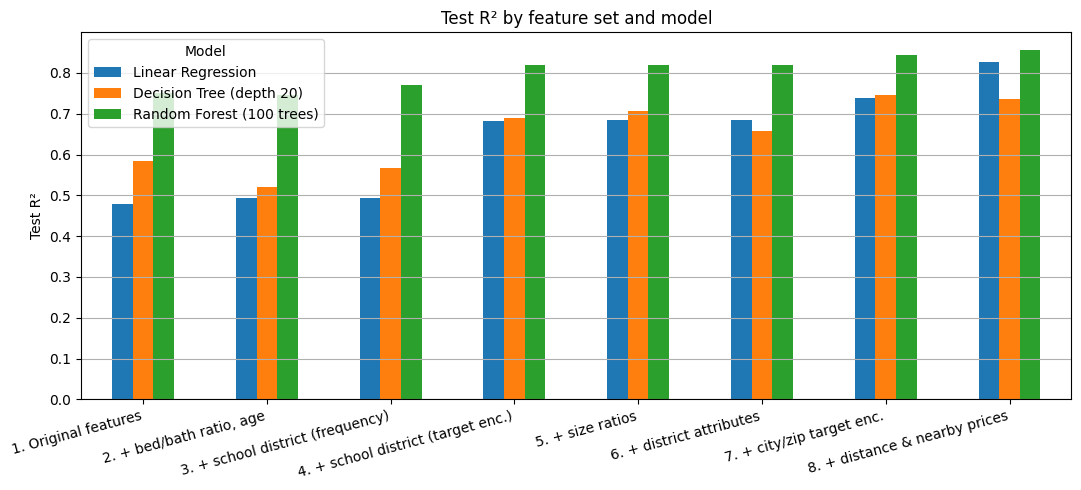

In [20]:
r2_table.plot(kind="bar", figsize=(11, 5))
plt.title("Test R² by feature set and model")
plt.ylabel("Test R²")
plt.xlabel("")
plt.xticks(rotation=15, ha="right")
plt.legend(title="Model")
plt.grid(axis="y")
plt.tight_layout()
plt.show()


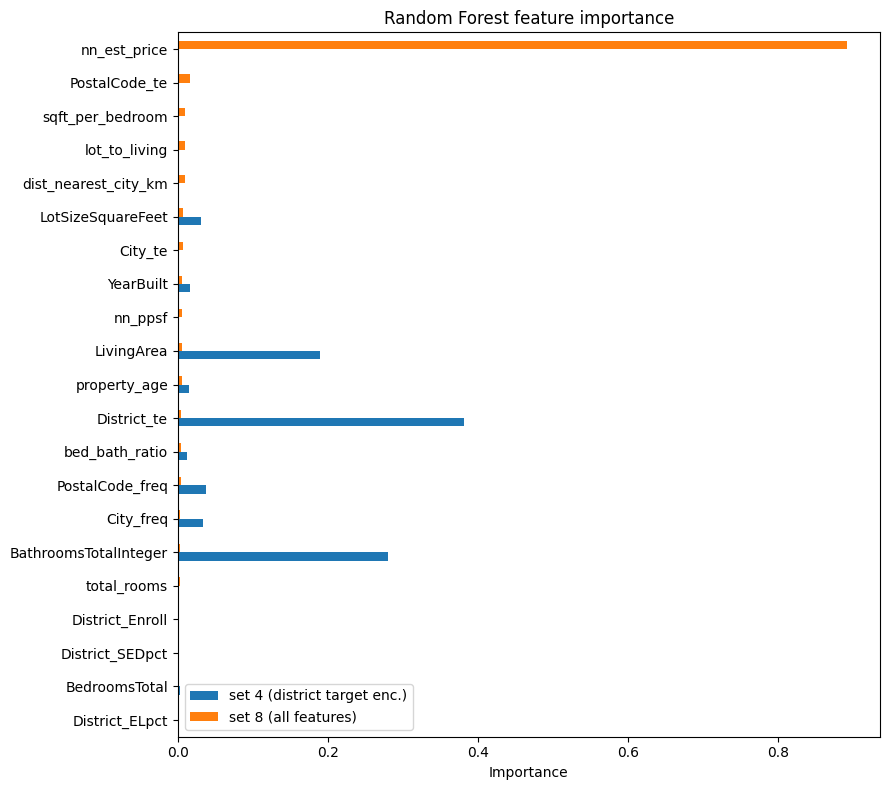

In [22]:
imp = pd.DataFrame({
    "set 4 (district target enc.)": rf_importances["4. + school district (target enc.)"],
    "set 8 (all features)": rf_importances["8. + distance & nearby prices"],
}).sort_values("set 8 (all features)", ascending=True)

imp.plot(kind="barh", figsize=(9, 8))
plt.title("Random Forest feature importance")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()